# Notebook 04 - Evaluación de generalización en múltiples cohortes

## Objetivos
- Cargar múltiples cohortes de pacientes (60k, 90k, 120k, 150k) con aumento incremental de datos.
- Verificar que no existan pacientes duplicados entre cohortes consecutivas (integridad datos).
- Seleccionar automáticamente variables de analíticas (LOINC) usando scripts de ingeniería de características.
- Cargar modelos pre-entrenados (RandomForest, SVM, XGBoost, MLP) desde el notebook 02.
- Evaluar el rendimiento de cada modelo en todas las cohortes sin reentrenamiento.
- Analizar la evolución de métricas de desempeño a medida que aumenta el tamaño de la cohorte.
- Investigar si el modelo generaliza bien o si el desempeño es resultado de similitud excesiva en datos sintéticos.

## Resumen de secciones y celdas

| Sección | Objetivo | Celdas (aprox.) |
|---|---|---|
| Setup | Importar librerías y configurar entorno | 2-3 |
| Carga de rutas | Definir directorios de proyecto y datos | 4 |
| Carga de cohortes | Cargar datasets de múltiples tamaños (60k, 90k, 120k, 150k) | 5-7 |
| Validación de integridad | Verificar que no haya pacientes repetidos entre cohortes consecutivas | 8-9 |
| Selección de variables | Ejecutar scripts automáticos para extraer solo analíticas (LOINC) | 10-11 |
| Pacientes nuevos por cohorte | Filtrar y mantener solo pacientes nuevos en cada incremento | 12-13 |
| Carga de modelos | Cargar preprocesador y modelos multmodelo entrenados del notebook 02 | 14 |
| Preprocesamiento test | Aplicar transformaciones pre-entrenadas a nuevas cohortes | 15 |
| Rendimiento por cohorte | Evaluar todos los modelos en cada cohorte con múltiples métricas | 16 |
| Evolución de métricas | Visualizar tendencia de desempeño (Accuracy, F1, ROC-AUC, etc.) en todas cohortes | 17 |
| Análisis de generalización | Discusión: ¿El modelo generaliza o es artefacto de datos sintéticos similares? | 18 |


## Setup

In [16]:
from pathlib import Path
from dotenv import load_dotenv, find_dotenv
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from funciones import obtener_info_valores_unicos, extraccion_columnas


from sklearn.compose import make_column_selector, ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn import set_config
from sklearn.metrics import classification_report

from xgboost import XGBClassifier
from interpret.glassbox import ExplainableBoostingClassifier
from interpret import show


## Carga de rutas

In [17]:
load_dotenv(find_dotenv())

PROJECT_ROOT = Path(find_dotenv()).parent.resolve()
print(f"PROJECT_ROOT set to: {PROJECT_ROOT}")
DATA_DIR = PROJECT_ROOT / 'data'

PROJECT_ROOT set to: C:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025


## Carga de las nuevas cohortes

In [18]:
datos_cohorte_30k = pd.read_csv(DATA_DIR / 'synthea_30k.csv', low_memory=False) #Los originales

In [19]:
datos_cohorte_60k = pd.read_csv(DATA_DIR / 'synthea-pt60k-lc-data-sel-convert.csv', low_memory=False)
datos_cohorte_90k = pd.read_csv(DATA_DIR / 'synthea-pt90k-lc-data-sel-convert.csv', low_memory=False)
datos_cohorte_120k = pd.read_csv(DATA_DIR / 'synthea-pt120k-lc-data-sel-convert.csv', low_memory=False)
datos_cohorte_150k = pd.read_csv(DATA_DIR / 'synthea-pt150k-lc-data-sel-convert.csv', low_memory=False)

In [20]:
y_60k = datos_cohorte_60k["label"].astype(int)
y_90k = datos_cohorte_90k["label"].astype(int)
y_120k = datos_cohorte_120k["label"].astype(int)
y_150k = datos_cohorte_150k["label"].astype(int)

Comprobación de que los nuevos pacientes son diferentes

In [21]:
comparaciones = [
    ("30k", datos_cohorte_30k, "60k", datos_cohorte_60k),
    ("60k", datos_cohorte_60k, "90k", datos_cohorte_90k),
    ("90k", datos_cohorte_90k, "120k", datos_cohorte_120k),
    ("120k", datos_cohorte_120k, "150k", datos_cohorte_150k),
]

coincidentes_por_par = {}

for nombre_a, df_a, nombre_b, df_b in comparaciones:
    ptnums_a = set(df_a["ptnum"].astype(str))
    ptnums_b = set(df_b["ptnum"].astype(str))
    coincidentes = sorted(ptnums_a.intersection(ptnums_b))
    coincidentes_por_par[(nombre_a, nombre_b)] = coincidentes

    print(f"\n--- Comparacion {nombre_a} vs {nombre_b} ---")
    print(f"Pacientes en {nombre_a}: {len(ptnums_a)}")
    print(f"Pacientes en {nombre_b}: {len(ptnums_b)}")
    print(f"Pacientes coincidentes en ambos datasets: {len(coincidentes)}")

    if coincidentes:
        print("Hay pacientes repetidos entre ambos datasets")
        if len(coincidentes) == len(ptnums_a):
            print(f"De hecho, todos los pacientes de {nombre_a} estan en {nombre_b}")
        else:
            print("Pacientes repetidos (ptnum):", coincidentes)
    else:
        print("No hay pacientes repetidos entre ambos datasets.")


--- Comparacion 30k vs 60k ---
Pacientes en 30k: 4221
Pacientes en 60k: 8484
Pacientes coincidentes en ambos datasets: 4221
Hay pacientes repetidos entre ambos datasets
De hecho, todos los pacientes de 30k estan en 60k

--- Comparacion 60k vs 90k ---
Pacientes en 60k: 8484
Pacientes en 90k: 12927
Pacientes coincidentes en ambos datasets: 8484
Hay pacientes repetidos entre ambos datasets
De hecho, todos los pacientes de 60k estan en 90k

--- Comparacion 90k vs 120k ---
Pacientes en 90k: 12927
Pacientes en 120k: 18209
Pacientes coincidentes en ambos datasets: 12927
Hay pacientes repetidos entre ambos datasets
De hecho, todos los pacientes de 90k estan en 120k

--- Comparacion 120k vs 150k ---
Pacientes en 120k: 18209
Pacientes en 150k: 22811
Pacientes coincidentes en ambos datasets: 18209
Hay pacientes repetidos entre ambos datasets
De hecho, todos los pacientes de 120k estan en 150k


## Selección de variables: Solo analíticas

Ejecutaremos el .py que selecciona automáticamente las variables que se declararon en la sección de ingeniería de caracteristicas médicas.

In [22]:
import subprocess

script_path = PROJECT_ROOT / "Variables_codif" / "LOINC" / "Scripts" / "json2csv_LOINC.py"

archivos = [
    ("60k", "synthea-pt60k-lc-data-sel-convert.csv", "synthea-pt60k-lc-data-sel-convert_solo_analiticas.csv"),
    ("90k", "synthea-pt90k-lc-data-sel-convert.csv", "synthea-pt90k-lc-data-sel-convert_solo_analiticas.csv"),
    ("120k", "synthea-pt120k-lc-data-sel-convert.csv", "synthea-pt120k-lc-data-sel-convert_solo_analiticas.csv"),
    ("150k", "synthea-pt150k-lc-data-sel-convert.csv", "synthea-pt150k-lc-data-sel-convert_solo_analiticas.csv"),
]

for nombre, input_file, output_file in archivos:
    input_path = DATA_DIR / input_file
    output_path = DATA_DIR / output_file

    subprocess.run(
        ["python", str(script_path), "--dataset", str(input_path), "--output", str(output_path)],
        check=True,
    )

    print(f"Conversión completada para {nombre}. Archivo generado: {output_path}")

Conversión completada para 60k. Archivo generado: C:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\data\synthea-pt60k-lc-data-sel-convert_solo_analiticas.csv
Conversión completada para 90k. Archivo generado: C:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\data\synthea-pt90k-lc-data-sel-convert_solo_analiticas.csv
Conversión completada para 120k. Archivo generado: C:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\data\synthea-pt120k-lc-data-sel-convert_solo_analiticas.csv
Conversión completada para 150k. Archivo generado: C:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\data\synthea-pt150k-lc-data-sel-convert_solo_analiticas.csv


### Pacientes de nuevo ingreso en cada dataset

In [23]:
df_60k_loinc = pd.read_csv(DATA_DIR / 'synthea-pt60k-lc-data-sel-convert_solo_analiticas.csv', low_memory=False)
df_90k_loinc = pd.read_csv(DATA_DIR / 'synthea-pt90k-lc-data-sel-convert_solo_analiticas.csv', low_memory=False)
df_120k_loinc = pd.read_csv(DATA_DIR / 'synthea-pt120k-lc-data-sel-convert_solo_analiticas.csv', low_memory=False)
df_150k_loinc = pd.read_csv(DATA_DIR / 'synthea-pt150k-lc-data-sel-convert_solo_analiticas.csv', low_memory=False)

y_60k = datos_cohorte_60k["label"].astype(int)
y_90k = datos_cohorte_90k["label"].astype(int)
y_120k = datos_cohorte_120k["label"].astype(int)
y_150k = datos_cohorte_150k["label"].astype(int)

ptnums_30k = set(datos_cohorte_30k["ptnum"].astype(str))
ptnums_60k = set(datos_cohorte_60k["ptnum"].astype(str))
ptnums_90k = set(datos_cohorte_90k["ptnum"].astype(str))
ptnums_120k = set(datos_cohorte_120k["ptnum"].astype(str))

mask_60k = ~df_60k_loinc["ptnum"].astype(str).isin(ptnums_30k)
mask_90k = ~df_90k_loinc["ptnum"].astype(str).isin(ptnums_60k)
mask_120k = ~df_120k_loinc["ptnum"].astype(str).isin(ptnums_90k)
mask_150k = ~df_150k_loinc["ptnum"].astype(str).isin(ptnums_120k)

df_60k_loinc = df_60k_loinc.loc[mask_60k].copy()
y_60k = y_60k.loc[mask_60k].copy()

df_90k_loinc = df_90k_loinc.loc[mask_90k].copy()
y_90k = y_90k.loc[mask_90k].copy()

df_120k_loinc = df_120k_loinc.loc[mask_120k].copy()
y_120k = y_120k.loc[mask_120k].copy()

df_150k_loinc = df_150k_loinc.loc[mask_150k].copy()
y_150k = y_150k.loc[mask_150k].copy()

print(f"Filas en df_60k_loinc tras filtrar: {df_60k_loinc.shape[0]}")
print(f"Longitud de y_60k tras filtrar: {len(y_60k)}")
print(f"Filas en df_90k_loinc tras filtrar: {df_90k_loinc.shape[0]}")
print(f"Longitud de y_90k tras filtrar: {len(y_90k)}")
print(f"Filas en df_120k_loinc tras filtrar: {df_120k_loinc.shape[0]}")
print(f"Longitud de y_120k tras filtrar: {len(y_120k)}")
print(f"Filas en df_150k_loinc tras filtrar: {df_150k_loinc.shape[0]}")
print(f"Longitud de y_150k tras filtrar: {len(y_150k)}")

df_60k_loinc.set_index('ptnum', inplace=True)
df_90k_loinc.set_index('ptnum', inplace=True)
df_120k_loinc.set_index('ptnum', inplace=True)
df_150k_loinc.set_index('ptnum', inplace=True)

Filas en df_60k_loinc tras filtrar: 4263
Longitud de y_60k tras filtrar: 4263
Filas en df_90k_loinc tras filtrar: 4443
Longitud de y_90k tras filtrar: 4443
Filas en df_120k_loinc tras filtrar: 5282
Longitud de y_120k tras filtrar: 5282
Filas en df_150k_loinc tras filtrar: 4602
Longitud de y_150k tras filtrar: 4602


## Carga de modelos y preprocesador pre-entrenados en el notebook 02

In [24]:
def to_int_types(df):
    return df.astype(int)

In [25]:
import joblib
from pathlib import Path


MODELOS_DIR = Path("models")

# Cargar preprocesador de laboratorio ya entrenado
preprocesador_lab = joblib.load(MODELOS_DIR / "preprocesamiento_lab.joblib")
print(f"✅ Preprocesador de laboratorio cargado")


# Cargar modelos múltiples tuneados (RandomForest, SVM, XGBoost, MLP)
mejor_modelo_analiticas = joblib.load(MODELOS_DIR / "mejor_modelo_analiticas_mlpclassifier.joblib")
print(f"✅ Modelo de analíticas cargado: {type(mejor_modelo_analiticas).__name__}")

print("\n📊 Objetos cargados correctamente. Listos para hacer predicciones sin reentrenar.")

✅ Preprocesador de laboratorio cargado
✅ Modelo de analíticas cargado: Pipeline

📊 Objetos cargados correctamente. Listos para hacer predicciones sin reentrenar.


## Rendimiento de los modelos sobre las nuevas cohortes

In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
)

datasets_eval = [
    ("60k", df_60k_loinc, y_60k),
    ("90k", df_90k_loinc, y_90k),
    ("120k", df_120k_loinc, y_120k),
    ("150k", df_150k_loinc, y_150k),
]

tablas_resultados = {}

for nombre_dataset, X_raw, y_eval in datasets_eval:
    resultados = []

    # Evaluar modelo de analíticas (LOINC)
    modelo = mejor_modelo_analiticas
    
    y_pred = modelo.predict(X_raw)

    y_proba = None
    if hasattr(modelo, "predict_proba"):
        y_proba = modelo.predict_proba(X_raw)[:, 1]

    fila = {
        "Modelo": "MLPClassifier (Analíticas)",
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Balanced_Accuracy": balanced_accuracy_score(y_eval, y_pred),
        "Precision_macro": precision_score(y_eval, y_pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_eval, y_pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_eval, y_pred, average="macro", zero_division=0),
        "F1_weighted": f1_score(y_eval, y_pred, average="weighted", zero_division=0),
    }

    if y_proba is not None:
        fila["ROC_AUC"] = roc_auc_score(y_eval, y_proba)
        fila["PR_AUC"] = average_precision_score(y_eval, y_proba)
    else:
        fila["ROC_AUC"] = None
        fila["PR_AUC"] = None

    resultados.append(fila)

    tabla_resultados = (
        pd.DataFrame(resultados)
        .sort_values("F1_weighted", ascending=False)
        .reset_index(drop=True)
    )

    tablas_resultados[nombre_dataset] = tabla_resultados
    print(f"\nResultados en cohorte {nombre_dataset}")
    display(tabla_resultados.round(4))

tabla_resultados_60k = tablas_resultados["60k"]
tabla_resultados_90k = tablas_resultados["90k"]
tabla_resultados_120k = tablas_resultados["120k"]
tabla_resultados_150k = tablas_resultados["150k"]


Resultados en cohorte 60k


,Modelo,Accuracy,Balanced_Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted,ROC_AUC,PR_AUC
0,MLPClassifier (Analíticas),0.8614,0.7909,0.8283,0.7909,0.8066,0.8572,0.9152,0.8061



Resultados en cohorte 90k


,Modelo,Accuracy,Balanced_Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted,ROC_AUC,PR_AUC
0,MLPClassifier (Analíticas),0.8688,0.7922,0.8254,0.7922,0.8067,0.8653,0.9121,0.7785



Resultados en cohorte 120k


,Modelo,Accuracy,Balanced_Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted,ROC_AUC,PR_AUC
0,MLPClassifier (Analíticas),0.8805,0.7954,0.8432,0.7954,0.8154,0.8761,0.9321,0.8083



Resultados en cohorte 150k


,Modelo,Accuracy,Balanced_Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted,ROC_AUC,PR_AUC
0,MLPClassifier (Analíticas),0.8657,0.7858,0.8298,0.7858,0.804,0.8609,0.9152,0.79


## Evolución del rendimiento en las distintas cohortes

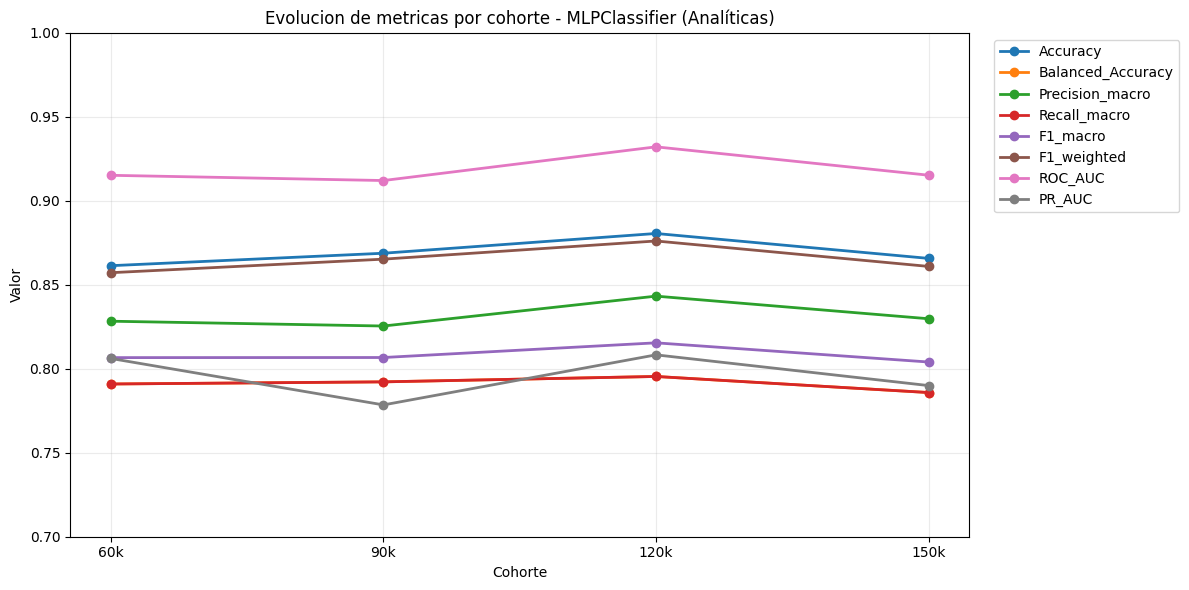

In [28]:
import matplotlib.pyplot as plt

modelo_objetivo = "MLPClassifier (Analíticas)"
cohortes = ["60k", "90k", "120k", "150k"]
metricas = [
    "Accuracy",
    "Balanced_Accuracy",
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "F1_weighted",
    "ROC_AUC",
    "PR_AUC",
]

filas_modelo = []
for cohorte in cohortes:
    fila = tablas_resultados[cohorte].loc[
        tablas_resultados[cohorte]["Modelo"] == modelo_objetivo,
        ["Modelo"] + metricas,
    ].copy()
    fila["Cohorte"] = cohorte
    filas_modelo.append(fila)

df_modelo = pd.concat(filas_modelo, ignore_index=True)
df_plot = df_modelo[["Cohorte"] + metricas].set_index("Cohorte").loc[cohortes]

plt.figure(figsize=(12, 6))
for metrica in metricas:
    plt.plot(df_plot.index, df_plot[metrica], marker="o", linewidth=2, label=metrica)

plt.ylim(0.70, 1.0)
plt.title(f"Evolucion de metricas por cohorte - {modelo_objetivo}")
plt.xlabel("Cohorte")
plt.ylabel("Valor")
plt.grid(True, alpha=0.25)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Muestra de que el modelo generaliza bien? o es meramente producto de que los datos están generados de forma demasiado similar